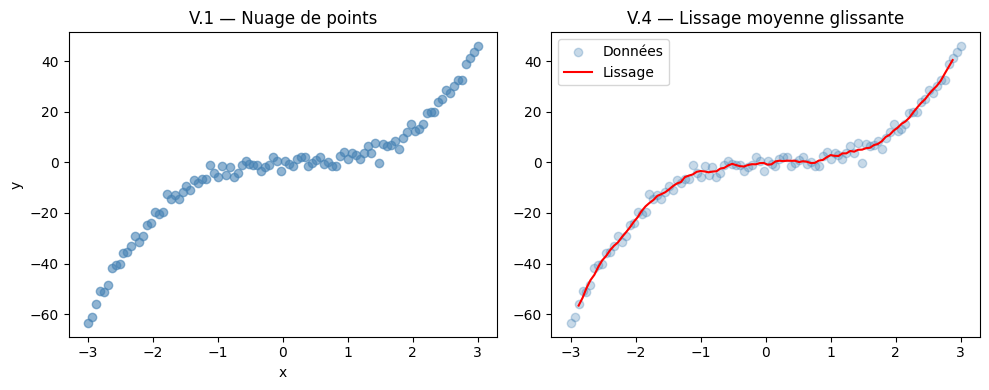

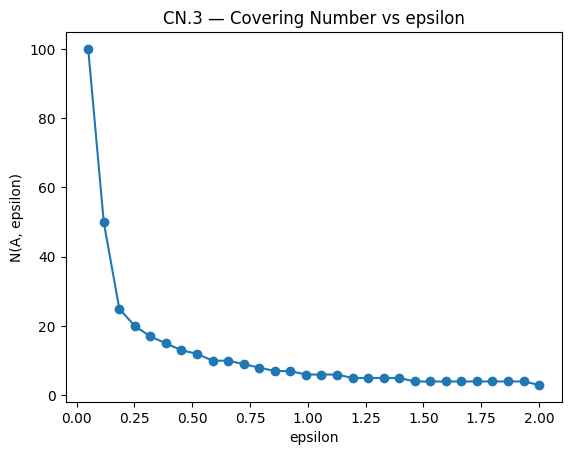

CN.4 — nmin pour eps0=0.3 : 20
CN.5 — n actuel = 100, suffisant
GN.1 — Gradient (forward): [  25.46381063  -61.28807744  150.58162757 -388.34048125]
GN.1 — Gradient (backward): [  25.46379064  -61.28812398  150.5813843  -388.34206295]
GN.1 — Gradient (central): [  25.46380064  -61.28810071  150.58150593 -388.3412721 ]


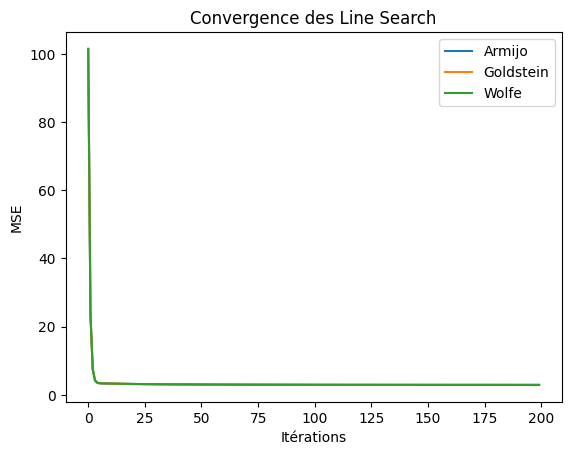

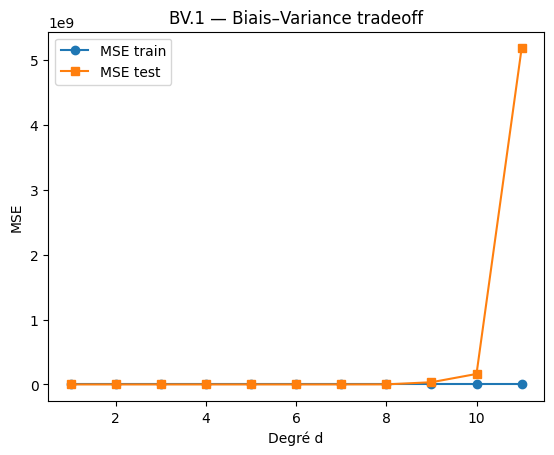

BV.3 — Degré optimal : d* = 3
CV.3 — Degré optimal par 5-fold CV : 3


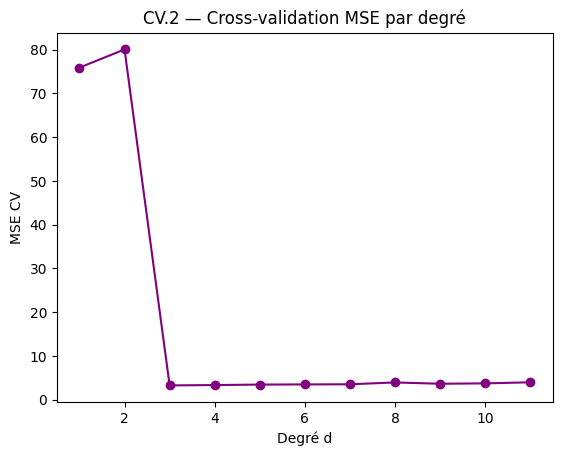

RG.1 — lambda=0.0001 -> MSE test = 6.4343
RG.1 — lambda=0.0100 -> MSE test = 6.4280
RG.1 — lambda=0.1000 -> MSE test = 6.3718
RG.1 — lambda=1.0000 -> MSE test = 5.8664
RG.1 — lambda=10.0000 -> MSE test = 3.7527
RG.3 — Meilleur lambda : 10.0


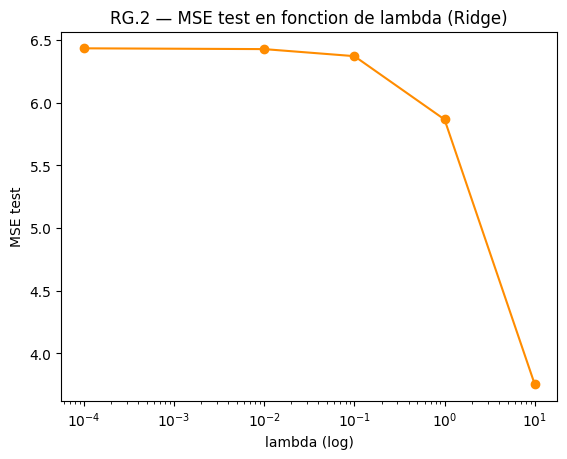

In [1]:
# TP1 - Ali Aqil
# Régression polynomiale, Covering Number, Gradient numérique,
# Line Search, Biais-Variance, Cross-validation et Régularisation

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

np.random.seed(42)

# ─────────────────────────────────────────────
# Données
# ─────────────────────────────────────────────

x = np.linspace(-3, 3, 100)
y = 2*x**3 - x**2 + 0.5*x + np.random.normal(0, 2, size=x.shape)

x_train, x_test = x[:70], x[70:]
y_train, y_test = y[:70], y[70:]


# ─────────────────────────────────────────────
# 1. Visualisation
# ─────────────────────────────────────────────

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(x, y, alpha=0.6, color='steelblue')
plt.xlabel('x'); plt.ylabel('y')
plt.title('V.1 — Nuage de points')

window = 5
y_smooth = np.convolve(y, np.ones(window)/window, mode='valid')
x_smooth = x[window//2 : -(window//2)]

plt.subplot(1, 2, 2)
plt.scatter(x, y, alpha=0.3, color='steelblue', label='Données')
plt.plot(x_smooth, y_smooth, color='red', label='Lissage')
plt.legend(); plt.title('V.4 — Lissage moyenne glissante')

plt.tight_layout()
plt.savefig('visualisation.png', dpi=150)
plt.show()


# ─────────────────────────────────────────────
# 2. Covering Number
# ─────────────────────────────────────────────

def greedy_cover(Z, eps):
    U = list(range(len(Z)))
    centers = []
    while U:
        c = U[0]
        centers.append(c)
        U = [i for i in U if np.linalg.norm(Z[i] - Z[c]) > eps]
    return centers, len(centers)

Z1 = x.reshape(-1, 1)
epsilons = np.linspace(0.05, 2.0, 30)
N_eps = [greedy_cover(Z1, e)[1] for e in epsilons]

plt.figure()
plt.plot(epsilons, N_eps, marker='o')
plt.xlabel('epsilon'); plt.ylabel('N(A, epsilon)')
plt.title('CN.3 — Covering Number vs epsilon')
plt.savefig('covering.png', dpi=150)
plt.show()

eps0 = 0.3
_, nmin = greedy_cover(Z1, eps0)
print(f"CN.4 — nmin pour eps0={eps0} : {nmin}")
print(f"CN.5 — n actuel = {len(x)}, {'suffisant' if len(x) >= nmin else 'insuffisant'}")


# ─────────────────────────────────────────────
# 3. Régression polynomiale + Gradient numérique
# ─────────────────────────────────────────────

def poly_predict(x, theta):
    return sum(theta[k] * x**k for k in range(len(theta)))

def mse(x, y, theta):
    return np.mean((poly_predict(x, theta) - y)**2)

def numerical_gradient(x, y, theta, h=1e-5, method='central'):
    grad = np.zeros_like(theta, dtype=float)
    for k in range(len(theta)):
        ek = np.zeros_like(theta, dtype=float)
        ek[k] = 1.0
        if method == 'forward':
            grad[k] = (mse(x, y, theta + h*ek) - mse(x, y, theta)) / h
        elif method == 'backward':
            grad[k] = (mse(x, y, theta) - mse(x, y, theta - h*ek)) / h
        elif method == 'central':
            grad[k] = (mse(x, y, theta + h*ek) - mse(x, y, theta - h*ek)) / (2*h)
    return grad

theta_test = np.array([0.0, 0.0, 0.0, 0.0])
for method in ['forward', 'backward', 'central']:
    g = numerical_gradient(x_train, y_train, theta_test, method=method)
    print(f"GN.1 — Gradient ({method}): {g}")


# ─────────────────────────────────────────────
# 4. Line Search
# ─────────────────────────────────────────────

def armijo(x, y, theta, grad, c1=1e-4, rho=0.5, alpha0=1.0):
    alpha = alpha0
    d = -grad
    J0 = mse(x, y, theta)
    slope = np.dot(grad, d)
    for _ in range(100):
        if mse(x, y, theta + alpha*d) <= J0 + c1*alpha*slope:
            break
        alpha *= rho
    return alpha

def goldstein(x, y, theta, grad, c=0.1, alpha0=1.0, max_iter=50):
    alpha = alpha0
    d = -grad
    J0 = mse(x, y, theta)
    slope = np.dot(grad, d)
    for _ in range(max_iter):
        J_new = mse(x, y, theta + alpha*d)
        upper = J0 + c * alpha * slope
        lower = J0 + (1-c) * alpha * slope
        if J_new <= upper and J_new >= lower:
            break
        elif J_new > upper:
            alpha *= 0.5
        else:
            alpha *= 2.0
    return alpha

def wolfe(x, y, theta, grad, c1=1e-4, c2=0.9, alpha0=1.0, max_iter=50):
    alpha = alpha0
    d = -grad
    J0 = mse(x, y, theta)
    slope = np.dot(grad, d)
    for _ in range(max_iter):
        J_new = mse(x, y, theta + alpha*d)
        if J_new > J0 + c1*alpha*slope:
            alpha *= 0.5
            continue
        g_new = numerical_gradient(x, y, theta + alpha*d)
        if abs(np.dot(g_new, d)) <= c2 * abs(slope):
            break
        alpha *= 1.5
    return alpha

def adaptive_ls(x, y, theta, grad, alpha, success_factor=1.2, fail_factor=0.5, threshold=1e-4):
    d = -grad
    J0 = mse(x, y, theta)
    J_new = mse(x, y, theta + alpha*d)
    rel_improvement = (J0 - J_new) / (abs(J0) + 1e-10)
    if rel_improvement > threshold:
        return alpha * success_factor
    return alpha * fail_factor

class SelfAdaptiveLS:
    def __init__(self, alpha0=1.0, window=5):
        self.alpha = alpha0
        self.history = []
        self.window = window

    def step(self, x, y, theta, grad):
        d = -grad
        J0 = mse(x, y, theta)
        J_new = mse(x, y, theta + self.alpha*d)
        self.history.append(J_new < J0)
        if len(self.history) > self.window:
            self.history.pop(0)
        rate = np.mean(self.history)
        if rate > 0.7:
            self.alpha = min(self.alpha * 1.3, 10.0)
        elif rate < 0.4:
            self.alpha = max(self.alpha * 0.6, 1e-8)
        return self.alpha

def gradient_descent(x, y, d_deg, ls_fn, n_iter=200):
    theta = np.zeros(d_deg + 1)
    costs = []
    for _ in range(n_iter):
        grad = numerical_gradient(x, y, theta)
        alpha = ls_fn(x, y, theta, grad)
        theta = theta - alpha * grad
        costs.append(mse(x, y, theta))
    return theta, costs

d_deg = 3
methods = {
    'Armijo':    lambda x, y, t, g: armijo(x, y, t, g),
    'Goldstein': lambda x, y, t, g: goldstein(x, y, t, g),
    'Wolfe':     lambda x, y, t, g: wolfe(x, y, t, g),
}

plt.figure()
for name, fn in methods.items():
    _, costs = gradient_descent(x_train, y_train, d_deg, fn)
    plt.plot(costs, label=name)

plt.xlabel('Itérations'); plt.ylabel('MSE')
plt.title('Convergence des Line Search')
plt.legend()
plt.savefig('linesearch.png', dpi=150)
plt.show()


# ─────────────────────────────────────────────
# 5. Biais - Variance
# ─────────────────────────────────────────────

degrees = list(range(1, 12))
mse_train_list, mse_test_list = [], []

for d in degrees:
    coeffs = np.polyfit(x_train, y_train, d)
    mse_train_list.append(np.mean((np.polyval(coeffs, x_train) - y_train)**2))
    mse_test_list.append(np.mean((np.polyval(coeffs, x_test)  - y_test)**2))

plt.figure()
plt.plot(degrees, mse_train_list, marker='o', label='MSE train')
plt.plot(degrees, mse_test_list,  marker='s', label='MSE test')
plt.xlabel('Degré d'); plt.ylabel('MSE')
plt.title('BV.1 — Biais–Variance tradeoff')
plt.legend()
plt.savefig('biais_variance.png', dpi=150)
plt.show()

d_star = degrees[np.argmin(mse_test_list)]
print(f"BV.3 — Degré optimal : d* = {d_star}")


# ─────────────────────────────────────────────
# 6a. Cross-validation K-fold
# ─────────────────────────────────────────────

kf = KFold(n_splits=5, shuffle=True, random_state=42)
mse_cv = []

for d in degrees:
    fold_errors = []
    for train_idx, val_idx in kf.split(x):
        coeffs = np.polyfit(x[train_idx], y[train_idx], d)
        fold_errors.append(np.mean((np.polyval(coeffs, x[val_idx]) - y[val_idx])**2))
    mse_cv.append(np.mean(fold_errors))

d_cv = degrees[np.argmin(mse_cv)]
print(f"CV.3 — Degré optimal par 5-fold CV : {d_cv}")

plt.figure()
plt.plot(degrees, mse_cv, marker='o', color='purple')
plt.xlabel('Degré d'); plt.ylabel('MSE CV')
plt.title('CV.2 — Cross-validation MSE par degré')
plt.savefig('crossval.png', dpi=150)
plt.show()


# ─────────────────────────────────────────────
# 6b. Régularisation Ridge
# ─────────────────────────────────────────────

lambdas = [0.0001, 0.01, 0.1, 1.0, 10.0]
ridge_errors = []

for lam in lambdas:
    model = make_pipeline(PolynomialFeatures(d_star), Ridge(alpha=lam))
    model.fit(x_train.reshape(-1, 1), y_train)
    y_hat = model.predict(x_test.reshape(-1, 1))
    ridge_errors.append(np.mean((y_hat - y_test)**2))
    print(f"RG.1 — lambda={lam:.4f} -> MSE test = {ridge_errors[-1]:.4f}")

best_lambda = lambdas[np.argmin(ridge_errors)]
print(f"RG.3 — Meilleur lambda : {best_lambda}")

plt.figure()
plt.semilogx(lambdas, ridge_errors, marker='o', color='darkorange')
plt.xlabel('lambda (log)'); plt.ylabel('MSE test')
plt.title('RG.2 — MSE test en fonction de lambda (Ridge)')
plt.savefig('ridge.png', dpi=150)
plt.show()